In [12]:
!pip uninstall -y -q torchao
!pip install -q sentencepiece

In [3]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"       # one GPU -> real batch size 8, as in the paper
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import subprocess, time, gc, shutil, inspect, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support)
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, Trainer,
                          TrainingArguments, EarlyStoppingCallback, set_seed)
from peft import LoraConfig, TaskType, get_peft_model
warnings.filterwarnings("ignore")

REPO = "/kaggle/working/senti-matrix"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/ELTE-DSED/senti-matrix.git", REPO], check=True)

OUT = "/kaggle/working/outputs"
os.makedirs(OUT, exist_ok=True)

SEEDS = [42]        # use [42, 43, 44] to report mean ± std like the paper (about 3x longer)
HAS_GPU = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "NONE - turn on a GPU in Settings")

Cloning into '/kaggle/working/senti-matrix'...


GPU: Tesla T4


Total: 9613
label
1    4963
0    4650
Name: count, dtype: int64
Train 7690 | Val 961 | Test 962


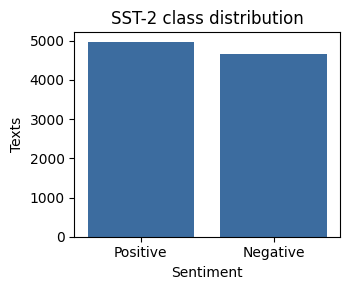

In [4]:
df = pd.read_csv(f"{REPO}/Dataset/SST-2 (2 Classes).csv", encoding="ISO-8859-1")
df = df[["Text", "Sentiment"]].dropna()
df["label"] = df["Sentiment"].astype(int)
print("Total:", len(df)); print(df["label"].value_counts())

train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df["Text"].tolist(), df["label"].tolist(),
    test_size=0.2, random_state=42, stratify=df["label"])
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels)
print(f"Train {len(train_texts)} | Val {len(val_texts)} | Test {len(test_texts)}")   # paper: 7690 / 961 / 962

CLASS_NAMES = ["Negative", "Positive"]
fig, ax = plt.subplots(figsize=(3.6, 3))
sns.countplot(x=df["label"].map(dict(enumerate(CLASS_NAMES))), ax=ax, color="#2b6cb0")
ax.set_title("SST-2 class distribution"); ax.set_xlabel("Sentiment"); ax.set_ylabel("Texts")
plt.tight_layout(); plt.savefig(f"{OUT}/class_distribution.png", dpi=200); plt.show()

In [5]:
class SentimentDataset(torch.utils.data.Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.labels[i])
        return item
    def __len__(self):
        return len(self.labels)

# Paper values: Table 4, LoRA rows (mean, std)
MODELS = {
    "DistilBERT": dict(
        name="distilbert-base-uncased", targets=["q_lin", "v_lin", "out_lin"],
        paper={"Accuracy": (89.02, 0.95), "Precision": (90.53, 2.70), "Recall": (88.13, 3.96),
               "F1": (89.22, 1.18), "Similarity": (90.76, 0.71), "Confidence": (92.06, 2.74),
               "ECE": (3.86, 1.71), "Brier": (0.17, 0.01),
               "Params": "758K", "Time": 195, "GPU": 0.46}),
    "RoBERTa": dict(
        name="roberta-base", targets=["query", "value", "output.dense"],
        paper={"Accuracy": (93.28, 0.91), "Precision": (93.42, 1.60), "Recall": (93.64, 2.14),
               "F1": (93.51, 0.91), "Similarity": (94.28, 0.61), "Confidence": (95.67, 2.68),
               "ECE": (3.15, 1.04), "Brier": (0.11, 0.01),
               "Params": "1.20M", "Time": 392, "GPU": 0.92}),
}

for key, cfg in MODELS.items():
    tok = AutoTokenizer.from_pretrained(cfg["name"])
    def enc(texts, tok=tok):
        return tok(texts, truncation=True, padding=True, max_length=512)
    cfg["data"] = {"train": SentimentDataset(enc(train_texts), train_labels),
                   "val":   SentimentDataset(enc(val_texts), val_labels),
                   "test":  SentimentDataset(enc(test_texts), test_labels)}
print("Tokenized.")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenized.


In [6]:
def metrics_from_logits(logits, labels):
    logits = np.asarray(logits, dtype=np.float64); labels = np.asarray(labels)
    z = logits - logits.max(axis=1, keepdims=True)
    proba = np.exp(z); proba /= proba.sum(axis=1, keepdims=True)
    preds = proba.argmax(1); n, C = proba.shape
    onehot = np.eye(C)[labels]
    p_true = proba[np.arange(n), labels]
    prec, rec, f1, _ = precision_recall_fscore_support(labels, preds, average="macro", zero_division=0)

    conf_max = proba.max(1); correct = (preds == labels).astype(float)
    edges = np.linspace(0, 1, 11); ece = 0.0                    # 10 equal-width bins
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf_max > lo) & (conf_max <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf_max[m].mean())
    return {"Accuracy": correct.mean() * 100,
            "Precision": prec * 100, "Recall": rec * 100, "F1": f1 * 100,       # macro, as in the paper
            "Similarity": (p_true / np.linalg.norm(proba, axis=1)).mean() * 100,  # cosine vs one-hot
            "Confidence": p_true.mean() * 100,                                    # paper: true-class prob
            "ECE": ece * 100,
            "Brier": ((proba - onehot) ** 2).sum(1).mean()}

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    return metrics_from_logits(logits, labels)

def make_args(**kw):
    params = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "warmup_ratio" in kw and "warmup_ratio" not in params:
        kw["warmup_steps"] = kw.pop("warmup_ratio")
    dropped = [k for k in kw if k not in params]
    for k in dropped:
        kw.pop(k)
    if dropped:
        print("dropped unsupported args ->", dropped)
    return TrainingArguments(**kw)

In [7]:
def run_lora(key, seed):
    cfg, d = MODELS[key], MODELS[key]["data"]
    set_seed(seed)
    if HAS_GPU:
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    model = AutoModelForSequenceClassification.from_pretrained(cfg["name"], num_labels=2)
    lcfg = LoraConfig(task_type=TaskType.SEQ_CLS, r=6, lora_alpha=12, lora_dropout=0.2,
                      target_modules=cfg["targets"], bias="none", modules_to_save=["classifier"])
    model = get_peft_model(model, lcfg)
    model.print_trainable_parameters()
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    ckpt = f"/kaggle/working/ckpt_{key}_{seed}"
    args = make_args(
        output_dir=ckpt, eval_strategy="epoch", save_strategy="epoch",
        learning_rate=3e-4, per_device_train_batch_size=8, per_device_eval_batch_size=16,
        num_train_epochs=10, weight_decay=0.05, warmup_ratio=0.1,
        logging_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="eval_loss", greater_is_better=False,
        report_to="none", seed=seed, fp16=HAS_GPU, gradient_accumulation_steps=1,
        max_grad_norm=1.0, save_total_limit=2, lr_scheduler_type="cosine",
        dataloader_pin_memory=False, remove_unused_columns=True)
    trainer = Trainer(model=model, args=args, train_dataset=d["train"], eval_dataset=d["val"],
                      compute_metrics=compute_metrics,
                      callbacks=[EarlyStoppingCallback(early_stopping_patience=3)])
    trainer.train()
    train_time = time.time() - t0
    gpu_gb = torch.cuda.max_memory_allocated() / 1024**3 if HAS_GPU else 0.0

    pred = trainer.predict(d["test"])
    out = dict(metrics=metrics_from_logits(pred.predictions, pred.label_ids),
               labels=np.asarray(pred.label_ids), preds=pred.predictions.argmax(-1),
               history=list(trainer.state.log_history),
               trainable=trainable, time=train_time, gpu=gpu_gb)
    del trainer, model; gc.collect()
    if HAS_GPU: torch.cuda.empty_cache()
    shutil.rmtree(ckpt, ignore_errors=True)
    return out

results = {k: [] for k in MODELS}
for key in MODELS:
    for seed in SEEDS:
        print(f"\n===== LoRA {key} | seed {seed} =====")
        results[key].append(run_lora(key, seed))
        m = results[key][-1]["metrics"]
        print(f"TEST -> acc {m['Accuracy']:.2f} | macro-F1 {m['F1']:.2f} | "
              f"{results[key][-1]['time']:.0f}s | {results[key][-1]['gpu']:.2f} GB")


===== LoRA DistilBERT | seed 42 =====


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,200,386 || all params: 125,847,556 || trainable%: 0.9538


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Similarity,Confidence,Ece,Brier
1,0.422969,0.249816,92.091571,92.178653,92.184140,92.091563,92.805658,88.374709,2.554210,0.134884
2,0.251327,0.322609,92.195630,92.235140,92.150538,92.180694,92.852587,91.827760,6.220534,0.138212
3,0.202111,0.285328,92.403746,92.443891,92.358871,92.389209,93.157429,92.053746,5.851407,0.131109
4,0.157370,0.405803,90.738814,91.349232,90.551075,90.667510,91.255048,90.264859,7.812801,0.170280


TEST -> acc 92.00 | macro-F1 92.00 | 262s | 0.90 GB


In [8]:
METRICS = ["Accuracy", "Precision", "Recall", "F1", "Similarity", "Confidence", "ECE", "Brier"]

def fmt(vals, d):
    s = f"{np.mean(vals):.{d}f}"
    return s + (f" ± {np.std(vals, ddof=1):.{d}f}" if len(vals) > 1 else "")

all_rows = []
for key, cfg in MODELS.items():
    runs, rows = results[key], []
    for m in METRICS:
        dp, do = (2, 3) if m == "Brier" else (2, 2)
        vals = [r["metrics"][m] for r in runs]
        pm, ps = cfg["paper"][m]
        diff = np.mean(vals) - pm
        rows.append([m, f"{pm:.{dp}f} ± {ps:.{dp}f}", fmt(vals, do), f"{diff:+.{do}f}",
                     "yes" if abs(diff) <= ps else "no"])
    rows.append(["Trainable params", cfg["paper"]["Params"], f"{runs[0]['trainable']:,}", "", ""])
    rows.append(["Training time (s)", str(cfg["paper"]["Time"]), fmt([r["time"] for r in runs], 0), "", ""])
    rows.append(["Peak GPU memory (GB)", f"{cfg['paper']['GPU']:.2f}", fmt([r["gpu"] for r in runs], 2), "", ""])
    t = pd.DataFrame(rows, columns=["Metric", "Paper (LoRA)", "Ours", "Difference", "Within paper ±std"])
    print(f"\nLoRA-{key}  |  SST-2  |  runs: {len(SEEDS)} (seeds {SEEDS})")
    display(t)
    t.insert(0, "Model", f"LoRA-{key}"); all_rows.append(t)

pd.concat(all_rows).to_csv(f"{OUT}/lora_replication_results.csv", index=False)


LoRA-DistilBERT  |  SST-2  |  runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,89.02 ± 0.95,88.05,-0.97,no
1,Precision,90.53 ± 2.70,88.22,-2.31,yes
2,Recall,88.13 ± 3.96,87.93,-0.20,yes
3,F1,89.22 ± 1.18,88.00,-1.22,no
4,Similarity,90.76 ± 0.71,90.63,-0.13,yes
5,Confidence,92.06 ± 2.74,83.42,-8.64,no
6,ECE,3.86 ± 1.71,1.73,-2.13,no
7,Brier,0.17 ± 0.01,0.170,-0.000,yes
8,Trainable params,758K,"758,018",,
9,Training time (s),195,122,,



LoRA-RoBERTa  |  SST-2  |  runs: 1 (seeds [42])


,Metric,Paper (LoRA),Ours,Difference,Within paper ±std
0,Accuracy,93.28 ± 0.91,92.00,-1.28,no
1,Precision,93.42 ± 1.60,92.11,-1.31,yes
2,Recall,93.64 ± 2.14,92.10,-1.54,yes
3,F1,93.51 ± 0.91,92.00,-1.51,no
4,Similarity,94.28 ± 0.61,93.33,-0.95,no
5,Confidence,95.67 ± 2.68,88.94,-6.73,no
6,ECE,3.15 ± 1.04,1.95,-1.20,no
7,Brier,0.11 ± 0.01,0.124,+0.014,no
8,Trainable params,1.20M,"1,200,386",,
9,Training time (s),392,262,,


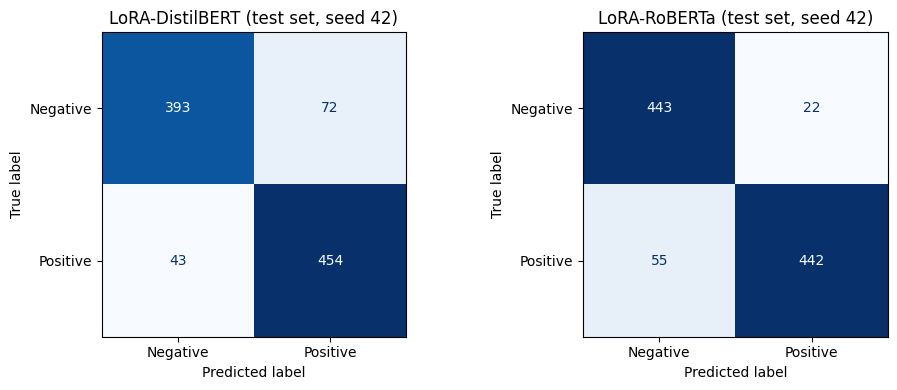

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key in zip(axes, MODELS):
    r = results[key][0]
    ConfusionMatrixDisplay.from_predictions(r["labels"], r["preds"], display_labels=CLASS_NAMES,
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"LoRA-{key} (test set, seed {SEEDS[0]})"); ax.grid(False)
plt.tight_layout(); plt.savefig(f"{OUT}/confusion_matrices.png", dpi=200); plt.show()

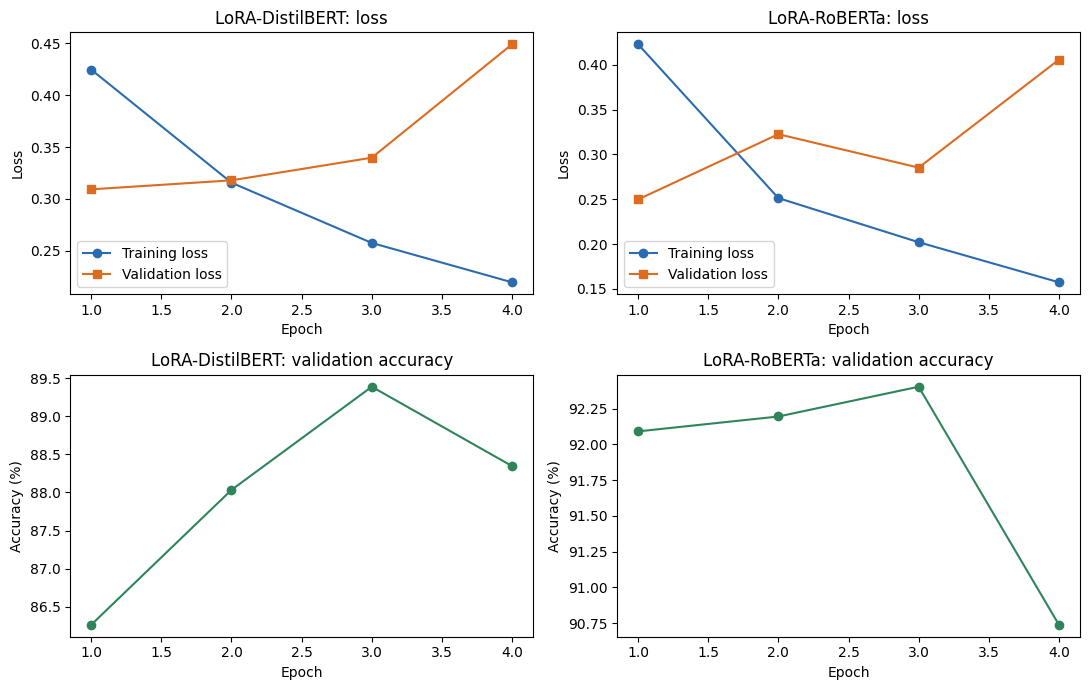

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, key in enumerate(MODELS):
    h = results[key][0]["history"]
    tr = [(l["epoch"], l["loss"]) for l in h if "loss" in l and "eval_loss" not in l]
    ev = [(l["epoch"], l["eval_loss"], l["eval_Accuracy"]) for l in h if "eval_loss" in l]
    ax = axes[0, j]
    ax.plot(*zip(*tr), marker="o", label="Training loss", color="#2b6cb0")
    ax.plot([e[0] for e in ev], [e[1] for e in ev], marker="s", label="Validation loss", color="#dd6b20")
    ax.set_title(f"LoRA-{key}: loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.legend()
    ax = axes[1, j]
    ax.plot([e[0] for e in ev], [e[2] for e in ev], marker="o", color="#2f855a")
    ax.set_title(f"LoRA-{key}: validation accuracy"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy (%)")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curves.png", dpi=200); plt.show()

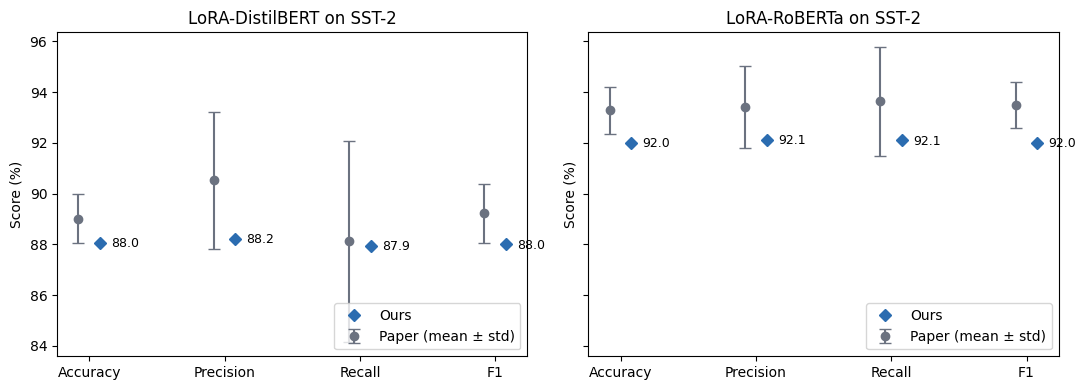

['lora_replication_results.csv', 'training_curves.png', 'ours_vs_paper.png', 'class_distribution.png', 'confusion_matrices.png']


In [11]:
names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, key in zip(axes, MODELS):
    paper = [MODELS[key]["paper"][n][0] for n in names]
    pstd = [MODELS[key]["paper"][n][1] for n in names]
    ours = [np.mean([r["metrics"][n] for r in results[key]]) for n in names]
    ax.errorbar(x - 0.08, paper, yerr=pstd, fmt="o", capsize=4, color="#6b7280", label="Paper (mean ± std)")
    ax.plot(x + 0.08, ours, "D", color="#2b6cb0", label="Ours")
    for xi, v in zip(x, ours):
        ax.annotate(f"{v:.1f}", (xi + 0.08, v), textcoords="offset points", xytext=(8, -3), fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(names)
    ax.set_title(f"LoRA-{key} on SST-2"); ax.set_ylabel("Score (%)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/ours_vs_paper.png", dpi=200); plt.show()
print(os.listdir(OUT))